# Workshop 2: reusing public data (GEO) and finding what differs between tumour and normal
*Curating Cancer Data, workshop 2*

**Aim.** There is a huge amount of cancer -omics data in the public domain that has been generated by someone else. Today you take a public RNA-seq study from the Gene Expression Omnibus (GEO), **GSE50760**: colorectal cancer samples with matched normal colon and liver metastasis from the same patients. You will download it yourself, check what you actually received, explore it with PCA and t-SNE, and then ask a real biological question: *which genes differ between tumour and normal, and what do those genes have in common?*
Everything is in Python.

**Before you start.** You should already have done the web-tools worksheet (the "manual" version: pasting gene lists into Enrichr, g:Profiler and MetaboAnalyst). Section 5.5 repeats part of it in code, so you can compare the two ways of working.

**Where to run it.** The easiest way is **Google Colab** ([open this notebook in Colab](https://colab.research.google.com/github/shorthouse-lab/Cancer_Omics_Workshops/blob/main/Workshop2/W2_GEO_student_coding.ipynb)): it runs in your browser, needs nothing installed, and sets up the extra packages for you. You can also run it locally if PyDESeq2 (0.5 or newer) and gseapy are already installed.

**How this notebook works.**
- Run each code cell in order (click it, then press Shift+Enter).
- Some cells contain gaps marked `____` (or `____` inside quotes). **Replace each `____` with the correct value, then run the cell.** The comments tell you what to put.
- If a cell gives an error, read the message (the last line is the useful one), check your gaps, and ask if you are stuck for more than a few minutes.
- Downloads go to a folder called `geo_cache` next to this notebook, and are skipped if the file is already there. **If a download fails** (NCBI sometimes blocks automated requests, especially when a whole room downloads at once), unzip the `geo_cache` zip from Moodle next to this notebook and run the cell again.

**Python cheat sheet (new things since workshop 1).**

| you see | it means |
|---|---|
| `df.loc[rows, cols]` | pick rows and columns of a table by label |
| `df.T` | flip a table (rows become columns) |
| `df["col"].str.contains("x")` | True for each row whose text includes `x` |
| `df["col"].map({"a": 1})` | translate values using a dictionary |
| `df.groupby("col")["y"].mean()` | average of `y` within each group of `col` |
| `df.sort_values("col")` | sort rows by a column |
| `np.log2(x)`, `np.log10(x)` | logarithms |
| `df.isin(list)` | True where the value is in the list |

| part | topic | time |
|---|---|---|
| 1 | Find and judge a public dataset: GEO, accessions, metadata | 15 min |
| 2 | Download and harmonise the counts: gene IDs, library size, filtering | 20 min |
| 3 | QC and exploration: PCA, clustering heatmap, t-SNE | 30 min |
| 4 | Differential expression with PyDESeq2: volcano plot | 30 min |
| 5 | Enrichment: what do the changed genes have in common? | 20 min |
| 6 | Pathway figures: top pathways from ORA and GSEA | 10 min |

## 0. Setup

In [35]:
## Setup: load standard modules (and check PyDESeq2 and gseapy are installed)
import subprocess, sys, json, re, gzip, time, platform, urllib.request
from pathlib import Path
# This notebook needs PyDESeq2 0.5 or newer (older versions use a different design syntax and fail on current pandas/anndata).
from importlib.metadata import version, PackageNotFoundError
IN_COLAB = "google.colab" in sys.modules          # True when running in Google Colab in your browser
def pydeseq2_problem():
    """Return a short description of what is wrong with the PyDESeq2 / gseapy install, or '' if all is well."""
    try:
        if tuple(int(x) for x in version("pydeseq2").split(".")[:2]) < (0, 5):
            return "PyDESeq2 is version " + version("pydeseq2") + " but this workshop needs 0.5 or newer."
        import gseapy
    except PackageNotFoundError:
        return "PyDESeq2 is not installed."
    except ImportError:
        return "gseapy is not installed."
    return ""
problem = pydeseq2_problem()
if problem and IN_COLAB:
    # Colab is a temporary machine in the cloud, so installing here cannot harm anything on your laptop.
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pydeseq2>=0.5", "gseapy"], check=True)
    problem = pydeseq2_problem()
if problem:
    raise RuntimeError(problem + "\nEasiest fix: open this notebook in Google Colab (link at the top of the notebook and on Moodle); it installs what it needs by itself."
                       "\nOn your own computer: ask for help rather than upgrading packages in your main Python, because that can break other software.")
import pydeseq2, gseapy
print("PyDESeq2", version("pydeseq2"), "| gseapy", version("gseapy"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
CACHE = Path("geo_cache"); CACHE.mkdir(exist_ok=True)
GSE = "GSE50760"                      # the GEO series we will reuse
PROVENANCE = {"series": GSE, "run_date": time.strftime("%Y-%m-%d")}   # we will fill this in as we go


MIRROR = "https://raw.githubusercontent.com/shorthouse-lab/Cancer_Omics_Workshops/main/Workshop2/geo_cache/"   # course copy of the data files (tried first, then NCBI)

def fetch(url, dest):
    """Download url to dest (skipped if the file is already there). Tries the course copy first (if MIRROR is set), then NCBI."""
    dest = Path(dest)
    if dest.exists() and dest.stat().st_size > 0:
        print("already have:", dest.name); return dest
    if MIRROR:
        try:
            with urllib.request.urlopen(MIRROR.rstrip("/") + "/" + dest.name, timeout=60) as r:
                data = r.read()
            if data[:1] != b"<":
                dest.write_bytes(data); print("downloaded from the course copy:", dest.name); return dest
        except Exception:
            pass                                  # fall back to NCBI below
    req = urllib.request.Request(url, headers={"User-Agent": "teaching-notebook"})
    try:
        with urllib.request.urlopen(req, timeout=120) as r:
            data = r.read()
        if data[:1] == b"<":                      # a web page (for example a robot check), not a data file
            raise ValueError("received a web page instead of the data file")
        dest.write_bytes(data)
    except Exception as e:
        raise RuntimeError(f"Download failed ({type(e).__name__}: {e}).\n"
                           "If NCBI is slow, unreachable, or asks you to prove you are not a robot (it can when many people download at once), ask for the geo_cache zip on Moodle and unzip it next to this notebook (in Colab, drag the unzipped files into a folder called geo_cache in the file panel).") from e
    print("downloaded:", dest.name, round(dest.stat().st_size / 1e6, 2), "MB")
    return dest

print("pydeseq2", pydeseq2.__version__, "| gseapy", gseapy.__version__, "| python", platform.python_version())

PyDESeq2 0.5.4 | gseapy 1.3.2
pydeseq2 0.5.4 | gseapy 1.3.2 | python 3.11.8


## Part 1. Find and judge a public dataset

### 1.1 What is GEO, and what is in it?

**In plain English.** GEO (the Gene Expression Omnibus, run by NCBI) is a public archive where authors deposit their data when they publish.
Its names are worth learning, because they tell you what you are looking at:

| prefix | stands for | example | what it is |
|---|---|---|---|
| `GSE` | series | GSE50760 | a whole study (the thing you cite) |
| `GSM` | sample | GSM1234567 | one sample in a study |
| `GPL` | platform | GPL11154 | the array or sequencer used |
| `SRP`, `SRX`, `SRR` | SRA study, experiment, run | SRR1234567 | the **raw reads**, stored in a different archive (SRA) |

GEO holds the *processed* data and the descriptions the authors chose to write. The raw sequencing reads live in the SRA. Authors decide what processed
file to upload (counts, FPKM, something else), so two GEO studies can look completely different. For many human RNA-seq studies NCBI has **re-processed
the raw reads with one pipeline** and published a matrix of raw counts, which makes studies far easier to reuse. We will use that.

### 1.2 Download the sample metadata

Every GEO series has a text file called the *series matrix*, which holds one row of information per sample. Its web address follows a pattern: the series
folder is named after the accession with the **last three digits replaced by `nnn`** (so GSE50760 lives in `GSE50nnn`).

In [36]:
# Build the folder name: the accession with its last three characters replaced by "nnn".
STEM = GSE[:-3] + "nnn"
print(STEM)

matrix_url = f"https://ftp.ncbi.nlm.nih.gov/geo/series/{STEM}/{GSE}/matrix/{GSE}_series_matrix.txt.gz"
matrix_file = fetch(matrix_url, CACHE / f"{GSE}_series_matrix.txt.gz")

GSE50nnn
already have: GSE50760_series_matrix.txt.gz


In [37]:
# HELPER FUNCTION - just run this cell, no changes needed.
def parse_series_matrix(path):
    """Read the '!Sample_...' lines of a GEO series matrix into a samples x fields table."""
    keyed = {}
    with gzip.open(path, "rt", errors="replace") as f:
        for line in f:
            if line.startswith("!Sample_"):
                parts = line.rstrip("\n").split("\t")
                keyed.setdefault(parts[0][len("!Sample_"):], []).append([p.strip('"') for p in parts[1:]])
    # Some lines (older GEO submissions) hold fewer values than there are samples: pad them with empty text.
    n_samples = len(keyed["geo_accession"][0])
    for rowlist in keyed.values():
        for vals in rowlist:
            vals.extend([""] * (n_samples - len(vals)))
    cols = {}
    for key, rowlist in keyed.items():
        for i, vals in enumerate(rowlist):
            if key.startswith("characteristics"):             # lines like "tissue: colon"
                pairs = [v.split(": ", 1) if ": " in v else ["characteristic", v] for v in vals]
                names = {p[0] for p in pairs}
                if len(names) == 1:
                    cols[names.pop().strip()] = [p[1] for p in pairs]
                else:
                    cols[f"{key}_{i+1}"] = vals
            else:
                cols[key if i == 0 else f"{key}_{i+1}"] = vals
    return pd.DataFrame(cols)

In [38]:
# One row per sample. The GSM accession is the unique ID of each sample.
meta = parse_series_matrix(matrix_file).set_index("geo_accession")
print(meta.shape)                 # (number of samples, number of fields the authors filled in)
print(list(meta.columns))
meta.head()

(54, 38)
['title', 'status', 'submission_date', 'last_update_date', 'type', 'channel_count', 'source_name_ch1', 'organism_ch1', 'tissue', 'ajcc stage', 'molecule_ch1', 'extract_protocol_ch1', 'extract_protocol_ch1_2', 'taxid_ch1', 'data_processing', 'data_processing_2', 'data_processing_3', 'data_processing_4', 'data_processing_5', 'data_processing_6', 'platform_id', 'contact_name', 'contact_email', 'contact_phone', 'contact_department', 'contact_institute', 'contact_address', 'contact_city', 'contact_zip/postal_code', 'contact_country', 'data_row_count', 'instrument_model', 'library_selection', 'library_source', 'library_strategy', 'relation', 'relation_2', 'supplementary_file_1']


,title,status,submission_date,last_update_date,type,channel_count,source_name_ch1,organism_ch1,tissue,ajcc stage,molecule_ch1,extract_protocol_ch1,extract_protocol_ch1_2,taxid_ch1,data_processing,...,contact_phone,contact_department,contact_institute,contact_address,contact_city,contact_zip/postal_code,contact_country,data_row_count,instrument_model,library_selection,library_source,library_strategy,relation,relation_2,supplementary_file_1
geo_accession,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
GSM1228184,primary colorectal cancer AMC_2-1,Public on Aug 31 2014,Sep 11 2013,May 15 2019,SRA,1,primary colorectal cancer,Homo sapiens,primary colorectal cancer,Stage IV,total RNA,Total RNA was isolated by RNeasy Mini Kit (Qia...,Sequencing library was prepared using TruSeq R...,9606,Base calling was performed by Illumina Genome ...,...,+82-42-879-8107,Personalized Genomic Medicine Research Center,Korea Research Institutue of Bioscience & Biot...,"125 Gwahak-ro, Yuseong-gu, Daejeon 305-806, Korea",Daejeon,305-806,South Korea,0,Illumina HiSeq 2000,cDNA,transcriptomic,RNA-Seq,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,SRA: https://www.ncbi.nlm.nih.gov/sra?term=SRX...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM1228...
GSM1228185,primary colorectal cancer AMC_3-1,Public on Aug 31 2014,Sep 11 2013,May 15 2019,SRA,1,primary colorectal cancer,Homo sapiens,primary colorectal cancer,Stage IV,total RNA,Total RNA was isolated by RNeasy Mini Kit (Qia...,Sequencing library was prepared using TruSeq R...,9606,Base calling was performed by Illumina Genome ...,...,+82-42-879-8107,Personalized Genomic Medicine Research Center,Korea Research Institutue of Bioscience & Biot...,"125 Gwahak-ro, Yuseong-gu, Daejeon 305-806, Korea",Daejeon,305-806,South Korea,0,Illumina HiSeq 2000,cDNA,transcriptomic,RNA-Seq,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,SRA: https://www.ncbi.nlm.nih.gov/sra?term=SRX...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM1228...
GSM1228186,primary colorectal cancer AMC_5-1,Public on Aug 31 2014,Sep 11 2013,May 15 2019,SRA,1,primary colorectal cancer,Homo sapiens,primary colorectal cancer,Stage IV,total RNA,Total RNA was isolated by RNeasy Mini Kit (Qia...,Sequencing library was prepared using TruSeq R...,9606,Base calling was performed by Illumina Genome ...,...,+82-42-879-8107,Personalized Genomic Medicine Research Center,Korea Research Institutue of Bioscience & Biot...,"125 Gwahak-ro, Yuseong-gu, Daejeon 305-806, Korea",Daejeon,305-806,South Korea,0,Illumina HiSeq 2000,cDNA,transcriptomic,RNA-Seq,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,SRA: https://www.ncbi.nlm.nih.gov/sra?term=SRX...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM1228...
GSM1228187,primary colorectal cancer AMC_6-1,Public on Aug 31 2014,Sep 11 2013,May 15 2019,SRA,1,primary colorectal cancer,Homo sapiens,primary colorectal cancer,Stage IV,total RNA,Total RNA was isolated by RNeasy Mini Kit (Qia...,Sequencing library was prepared using TruSeq R...,9606,Base calling was performed by Illumina Genome ...,...,+82-42-879-8107,Personalized Genomic Medicine Research Center,Korea Research Institutue of Bioscience & Biot...,"125 Gwahak-ro, Yuseong-gu, Daejeon 305-806, Korea",Daejeon,305-806,South Korea,0,Illumina HiSeq 2000,cDNA,transcriptomic,RNA-Seq,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,SRA: https://www.ncbi.nlm.nih.gov/sra?term=SRX...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM1228...
GSM1228188,primary colorectal cancer AMC_7-1,Public on Aug 31 2014,Sep 11 2013,May 15 2019,SRA,1,primary colorectal cancer,Homo sapiens,primary colorectal cancer,Stage IV,total RNA,Total RNA was isolated by RNeasy Mini Kit (Qia...,Sequencing library was prepared using TruSeq R...,9606,Base calling was performed by Illumina Genome ...,...,+82-42-879-8107,Personalized Genomic Medicine Research Center,Korea Research Institutue of Bioscience & Biot...,"125 Gwahak-ro, Yuseong-gu, Daejeon 305-806, Korea",Daejeon,305-806,South Korea,0,Illumina HiSeq 2000,cDNA,transcriptomic,RNA-Seq,Bi

**Discussion.** What did the authors tell us about each sample, and what did they *not* tell us? Make a list of three things you would want to know before
trusting a comparison (think: patient age and sex, tumour stage, MSI status, when and where the sample was sequenced, RNA quality). Which of them can you
get from this table?

### 1.3 Turn the free text into a design table

For a comparison we need two clean columns: **tissue** (normal, primary, metastasis) and **patient**. The authors wrote these as free text, so we have to
extract them, and then *check* that we got them right.

In [39]:
meta.head()

,title,status,submission_date,last_update_date,type,channel_count,source_name_ch1,organism_ch1,tissue,ajcc stage,molecule_ch1,extract_protocol_ch1,extract_protocol_ch1_2,taxid_ch1,data_processing,...,contact_phone,contact_department,contact_institute,contact_address,contact_city,contact_zip/postal_code,contact_country,data_row_count,instrument_model,library_selection,library_source,library_strategy,relation,relation_2,supplementary_file_1
geo_accession,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
GSM1228184,primary colorectal cancer AMC_2-1,Public on Aug 31 2014,Sep 11 2013,May 15 2019,SRA,1,primary colorectal cancer,Homo sapiens,primary colorectal cancer,Stage IV,total RNA,Total RNA was isolated by RNeasy Mini Kit (Qia...,Sequencing library was prepared using TruSeq R...,9606,Base calling was performed by Illumina Genome ...,...,+82-42-879-8107,Personalized Genomic Medicine Research Center,Korea Research Institutue of Bioscience & Biot...,"125 Gwahak-ro, Yuseong-gu, Daejeon 305-806, Korea",Daejeon,305-806,South Korea,0,Illumina HiSeq 2000,cDNA,transcriptomic,RNA-Seq,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,SRA: https://www.ncbi.nlm.nih.gov/sra?term=SRX...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM1228...
GSM1228185,primary colorectal cancer AMC_3-1,Public on Aug 31 2014,Sep 11 2013,May 15 2019,SRA,1,primary colorectal cancer,Homo sapiens,primary colorectal cancer,Stage IV,total RNA,Total RNA was isolated by RNeasy Mini Kit (Qia...,Sequencing library was prepared using TruSeq R...,9606,Base calling was performed by Illumina Genome ...,...,+82-42-879-8107,Personalized Genomic Medicine Research Center,Korea Research Institutue of Bioscience & Biot...,"125 Gwahak-ro, Yuseong-gu, Daejeon 305-806, Korea",Daejeon,305-806,South Korea,0,Illumina HiSeq 2000,cDNA,transcriptomic,RNA-Seq,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,SRA: https://www.ncbi.nlm.nih.gov/sra?term=SRX...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM1228...
GSM1228186,primary colorectal cancer AMC_5-1,Public on Aug 31 2014,Sep 11 2013,May 15 2019,SRA,1,primary colorectal cancer,Homo sapiens,primary colorectal cancer,Stage IV,total RNA,Total RNA was isolated by RNeasy Mini Kit (Qia...,Sequencing library was prepared using TruSeq R...,9606,Base calling was performed by Illumina Genome ...,...,+82-42-879-8107,Personalized Genomic Medicine Research Center,Korea Research Institutue of Bioscience & Biot...,"125 Gwahak-ro, Yuseong-gu, Daejeon 305-806, Korea",Daejeon,305-806,South Korea,0,Illumina HiSeq 2000,cDNA,transcriptomic,RNA-Seq,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,SRA: https://www.ncbi.nlm.nih.gov/sra?term=SRX...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM1228...
GSM1228187,primary colorectal cancer AMC_6-1,Public on Aug 31 2014,Sep 11 2013,May 15 2019,SRA,1,primary colorectal cancer,Homo sapiens,primary colorectal cancer,Stage IV,total RNA,Total RNA was isolated by RNeasy Mini Kit (Qia...,Sequencing library was prepared using TruSeq R...,9606,Base calling was performed by Illumina Genome ...,...,+82-42-879-8107,Personalized Genomic Medicine Research Center,Korea Research Institutue of Bioscience & Biot...,"125 Gwahak-ro, Yuseong-gu, Daejeon 305-806, Korea",Daejeon,305-806,South Korea,0,Illumina HiSeq 2000,cDNA,transcriptomic,RNA-Seq,BioSample: https://www.ncbi.nlm.nih.gov/biosam...,SRA: https://www.ncbi.nlm.nih.gov/sra?term=SRX...,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM1228...
GSM1228188,primary colorectal cancer AMC_7-1,Public on Aug 31 2014,Sep 11 2013,May 15 2019,SRA,1,primary colorectal cancer,Homo sapiens,primary colorectal cancer,Stage IV,total RNA,Total RNA was isolated by RNeasy Mini Kit (Qia...,Sequencing library was prepared using TruSeq R...,9606,Base calling was performed by Illumina Genome ...,...,+82-42-879-8107,Personalized Genomic Medicine Research Center,Korea Research Institutue of Bioscience & Biot...,"125 Gwahak-ro, Yuseong-gu, Daejeon 305-806, Korea",Daejeon,305-806,South Korea,0,Illumina HiSeq 2000,cDNA,transcriptomic,RNA-Seq,Bi

In [40]:
# Join all the text fields of each sample into one lower-case string we can search.
text = meta.astype(str).agg(" ".join, axis=1).str.lower()

def tissue_from_text(t):
    # Fill in a word that appears only in the text of that kind of sample (look at the table above).
    if "metast" in t:
        return "metastasis"
    if "normal" in t:
        return "normal"
    if "primary" in t:
        return "primary"
    return "unknown"

meta["tissue"] = text.map(tissue_from_text)
print(meta["tissue"].value_counts())

tissue
primary       18
normal        18
metastasis    18
Name: count, dtype: int64


In [41]:
# Which column (if any) holds the patient? List the likely candidates.
print([c for c in meta.columns if re.search("patient|individual|subject|donor|case", c, re.I)])   # an empty list [] means no column is called that
print(meta["title"].head(6).tolist())                       # ...but the patient may be written inside the title

[]
['primary colorectal cancer AMC_2-1', 'primary colorectal cancer AMC_3-1', 'primary colorectal cancer AMC_5-1', 'primary colorectal cancer AMC_6-1', 'primary colorectal cancer AMC_7-1', 'primary colorectal cancer AMC_8-1']


In [42]:
# No column holds the patient, but the title does: "primary colorectal cancer AMC_2-1" is patient 2 (the "-1" at the end is the tissue).
# str.extract(pattern) returns the part of the text that matches the bracketed bit of the pattern (\d+ means "one or more digits").
# Fill in the text that comes just before the patient number in every title (look at the titles printed above).
meta["patient"] = meta["title"].str.extract(r"AMC_(\d+)-")[0]

# Is the design complete? Rows = patients, columns = tissue. Every cell should be 1 if each patient gave one sample of each kind.
design = pd.crosstab(meta["patient"], meta["tissue"])
design.head()

tissue,metastasis,normal,primary
patient,,,
10,1,1,1
12,1,1,1
13,1,1,1
17,1,1,1
18,1,1,1


## Part 2. Download and harmonise the counts

### 2.1 NCBI-generated raw counts

**In plain English.** The authors uploaded their own processed files. In addition, NCBI re-aligned the raw reads for many human RNA-seq studies with **one
common pipeline** and offers a matrix of **raw counts**: one row per gene, one column per sample (the GSM IDs). Two things to remember: these numbers are
NCBI's, not the authors', and the genes are named by **Entrez GeneID** (a number), not by Ensembl ID as in workshop 1. We also download NCBI's gene table (a small file from NCBI's FTP site)
that translates the numbers into gene symbols and gene types.

In [43]:
counts_url = f"https://www.ncbi.nlm.nih.gov/geo/download/?type=rnaseq_counts&acc={GSE}&format=file&file={GSE}_raw_counts_GRCh38.p13_NCBI.tsv.gz"
annot_url = "https://ftp.ncbi.nlm.nih.gov/gene/DATA/GENE_INFO/Mammalia/Homo_sapiens.gene_info.gz"   # NCBI Gene table: GeneID -> symbol and gene type
counts_file = fetch(counts_url, CACHE / f"{GSE}_raw_counts_GRCh38.p13_NCBI.tsv.gz")
annot_file = fetch(annot_url, CACHE / "Homo_sapiens.gene_info.gz")
PROVENANCE["counts_file"] = counts_file.name
PROVENANCE["annotation_file"] = annot_file.name

already have: GSE50760_raw_counts_GRCh38.p13_NCBI.tsv.gz
already have: Homo_sapiens.gene_info.gz


In [44]:
counts = pd.read_csv(counts_file, sep="\t", index_col=0)
print(counts.shape)            # (number of genes, number of samples)
counts.iloc[:5, :4]

(39376, 54)


,GSM1228184,GSM1228185,GSM1228186,GSM1228187
GeneID,,,,
100287102,1,1,0,3
653635,315,522,344,858
102466751,7,8,10,33
107985730,1,0,0,1
100302278,0,0,0,0


In [45]:
# Is this really a matrix of raw counts? Raw counts are whole numbers with many zeros. Look at the first 20 samples.
sub = counts.iloc[:, :20].to_numpy(dtype="float64")
print("min", sub.min(), " max", sub.max())
print("fraction of values that are whole numbers:", np.mean(np.isclose(sub, np.round(sub))))
print("fraction of values equal to exactly 0:", round(float(np.mean(sub == 0)), 3))

min 0.0  max 1519634.0
fraction of values that are whole numbers: 1.0
fraction of values equal to exactly 0: 0.333


### 2.2 Match the counts to the metadata

In [46]:
# The columns of the counts are GSM accessions, like the rows of `meta`. Are they the same set, and in the same order?
print("same samples:", set(counts.columns) == set(meta.index))
print("same order:", list(counts.columns) == list(meta.index))

# Put the metadata rows in the same order as the count columns.
meta = meta.loc[counts.columns]
assert list(counts.columns) == list(meta.index)

same samples: True
same order: True


### 2.3 Gene identifiers

##### Our genes are listed as numbers - these are ensembl gene IDs, which are not human readable, so we have to do a lookup to assign them to their names

In [47]:
annot = pd.read_csv(annot_file, sep="\t", usecols=["GeneID", "Symbol", "type_of_gene"], index_col="GeneID")
annot = annot.rename(columns={"type_of_gene": "GeneType"})          # same name as in the text below
print(annot.shape)
print(annot["GeneType"].value_counts().head(8))
annot.head(3)

(194084, 2)
GeneType
biological-region    128261
ncRNA                 22806
protein-coding        20601
pseudo                17512
snoRNA                 1199
unknown                1197
other                   846
rRNA                    785
Name: count, dtype: int64


,Symbol,GeneType
GeneID,,
1,A1BG,protein-coding
2,A2M,protein-coding
9,NAT1,protein-coding


In [48]:
# Goal: one row per gene SYMBOL, protein-coding genes only.
# Step 1: keep protein-coding genes that are in the counts matrix. (Look at the GeneType values printed above for the exact spelling.)
is_coding = annot["GeneType"] == "protein-coding"
keep_type = is_coding | (annot["Symbol"] == "XIST")      # XIST is the sex marker used in 3.4; NCBI lists it as non-coding, so we keep it too
pc = annot[keep_type & annot.index.isin(counts.index)].copy()

# Step 2: if several GeneIDs share a symbol, keep the one with the most reads overall.
pc["total_reads"] = counts.loc[pc.index].sum(axis=1)
pc = pc.sort_values("total_reads", ascending=False)        # highest first
pc = pc.drop_duplicates("Symbol")                           # keeps the first = highest

# Step 3: build the table we will use from now on: rows = gene symbols, columns = samples.
counts_pc = counts.loc[pc.index].copy()
counts_pc.index = pc["Symbol"].values

counts_pc.head()

,GSM1228184,GSM1228185,GSM1228186,GSM1228187,GSM1228188,GSM1228189,GSM1228190,GSM1228191,GSM1228192,GSM1228193,GSM1228194,GSM1228195,GSM1228196,GSM1228197,GSM1228198,...,GSM1228223,GSM1228224,GSM1228225,GSM1228226,GSM1228227,GSM1228228,GSM1228229,GSM1228230,GSM1228231,GSM1228232,GSM1228233,GSM1228234,GSM1228235,GSM1228236,GSM1228237
COX1,366940,272718,860657,663476,770715,1403530,521980,485379,403903,1519634,1252901,1406243,987674,375904,321464,...,226377,496628,458131,710223,520100,519700,590942,377287,653138,3051958,350577,423879,1792647,735399,597332
ND4,182101,118250,368927,248435,337912,660566,222880,165223,182416,676371,582777,610913,347456,154224,224113,...,100403,236755,308434,329991,188041,265984,345292,193681,301336,2101868,132675,263395,883263,364937,356013
COX3,178515,162921,348641,220897,255885,448872,162772,160909,171654,531475,349651,499454,303938,103055,204792,...,88257,171248,262625,285483,138771,178875,291744,144186,243668,1275563,85780,197417,570050,310707,255369
ATP6,165932,128293,213165,213941,249363,362377,167804,120531,129345,452443,316487,308737,235669,86971,178406,...,87313,167573,223092,274266,155574,156343,252745,102313,133590,1204568,84891,189553,462854,285843,254559
EEF1A1,353216,458593,160842,349094,279067,196610,191591,232593,230152,146468,118640,186956,293284,387276,139452,...,324163,231784,193942,292347,109414,183403,270178,212326,183177,102775,263022,183853,109265,282785,380240


**Discussion.** The mutation table in workshop 1 used gene symbols and the expression table used Ensembl IDs. Here the counts use Entrez GeneIDs. What can go wrong when two
datasets name genes differently? Why did we choose to keep only protein-coding genes, and what do we lose by doing so? (We made one exception, XIST. Why?)

### 2.4 Library size and detected genes

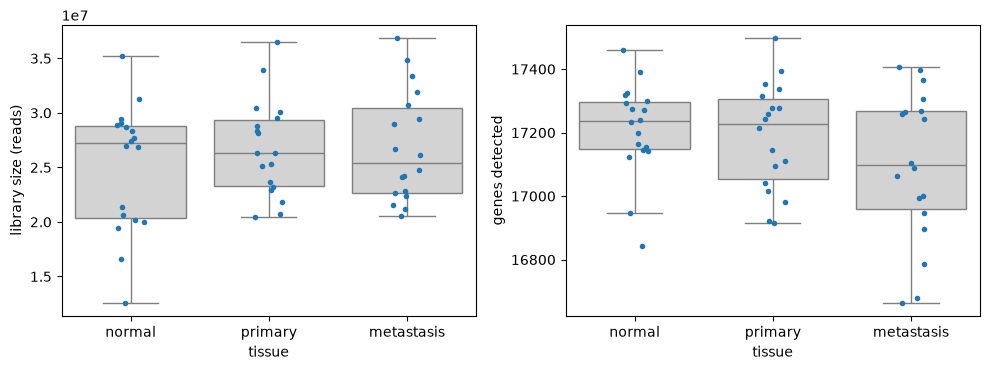

            count  mean  std   min   25%   50%   75%   max
tissue                                                    
metastasis    0.0  26.8  5.0  20.5  22.7  25.4  30.4  36.9
normal        0.0  25.0  5.8  12.6  20.3  27.2  28.8  35.2
primary       0.0  26.8  4.4  20.5  23.3  26.3  29.3  36.5


In [49]:
# Library size = total reads counted in each sample (use ALL genes in `counts`). Detected genes = genes with at least one read.
meta["lib_size"] = counts.sum(axis=0)                   # add up down each column
meta["genes_detected"] = (counts_pc > 0).sum(axis=0)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
order = ["normal", "primary", "metastasis"]
for a, col, lab in zip(ax, ["lib_size", "genes_detected"], ["library size (reads)", "genes detected"]):
    sns.boxplot(data=meta, x="tissue", y=col, order=order, ax=a, color="lightgrey", fliersize=0)
    sns.stripplot(data=meta, x="tissue", y=col, order=order, ax=a, size=4)
    a.set_ylabel(lab)
plt.tight_layout(); plt.show()
print((meta.groupby("tissue")["lib_size"].describe() / 1e6).round(1))

**Discussion.** How much does library size vary, and does it differ between tissues? If tumours were sequenced more deeply than normals, what would that do to a naive comparison of raw
counts? Which step in Part 3 and which feature of DESeq2 deal with this?

### 2.5 Remove genes that are almost never detected

Genes with nearly zero counts carry no usable information, and testing them costs statistical power. We keep a gene only if it has at least 10 reads in at least as many samples as the **smallest group**.

In [50]:
min_group = meta["tissue"].value_counts().min()
keep = (counts_pc >= 10).sum(axis=1) >= min_group          # for each gene, count the samples with >= 10 reads
counts_f = counts_pc.loc[keep]
print("genes before:", counts_pc.shape[0], "| after:", counts_f.shape[0])
PROVENANCE["gene_filter"] = f">=10 reads in >={min_group} samples; protein-coding; one GeneID per symbol"

genes before: 19401 | after: 15739


**Discussion.** The threshold (10 reads, smallest group size) is a *choice*. 10 is arbitrary - and there is no "best value" for a study, you may have to try different cutoffs

## Part 3. QC and exploration

### 3.1 Normalise and look: PCA

**In plain English.** For plots (not for the DE test) we correct for sequencing depth by turning counts into **log2 CPM**: divide each count by the sample's library size, multiply by a million, add 1 and take
log2. This is the same idea as in workshop 1.

In [51]:
# log2 CPM for ALL protein-coding genes (unfiltered), and for the filtered set we will use for plots.
logcpm_all = np.log2(counts_pc / meta["lib_size"] * 1e6 + 1)
logcpm = logcpm_all.loc[counts_f.index]
print(logcpm.shape)

(15739, 54)


In [52]:
# HELPER FUNCTIONS - just run this cell, no changes needed.
from sklearn.decomposition import PCA

def run_pca(X, n_components=10, n_genes=2000):
    """PCA on a genes x samples table using the n_genes most variable genes. Returns scores (samples x PCs) and variance explained."""
    top = X.var(axis=1).nlargest(n_genes).index
    S = X.loc[top].T
    pca = PCA(n_components=n_components).fit(S)
    scores = pd.DataFrame(pca.transform(S), index=X.columns, columns=[f"PC{i+1}" for i in range(n_components)])
    return scores, pca.explained_variance_ratio_

def plot_pca(scores, labels, title, ax=None, pcs=("PC1", "PC2")):
    """One point per sample, coloured by labels (categories -> colours, numbers -> colour scale)."""
    ax = ax or plt.gca()
    labels = pd.Series(labels).reindex(scores.index)
    if pd.api.types.is_numeric_dtype(labels):
        pts = ax.scatter(scores[pcs[0]], scores[pcs[1]], c=labels, s=18, cmap="viridis")
        plt.colorbar(pts, ax=ax, label=labels.name)
    else:
        labels = labels.fillna("unknown")
        groups = sorted(labels.unique())
        for g in groups:
            m = labels == g
            ax.scatter(scores.loc[m, pcs[0]], scores.loc[m, pcs[1]], s=18, alpha=0.8, label=str(g))
        if len(groups) <= 10:
            ax.legend(fontsize=8, markerscale=1.2)
    ax.set_xlabel(pcs[0]); ax.set_ylabel(pcs[1]); ax.set_title(title)

% of variation explained by PC1 to PC5: [46.7 15.5  8.7  3.9  2.7]


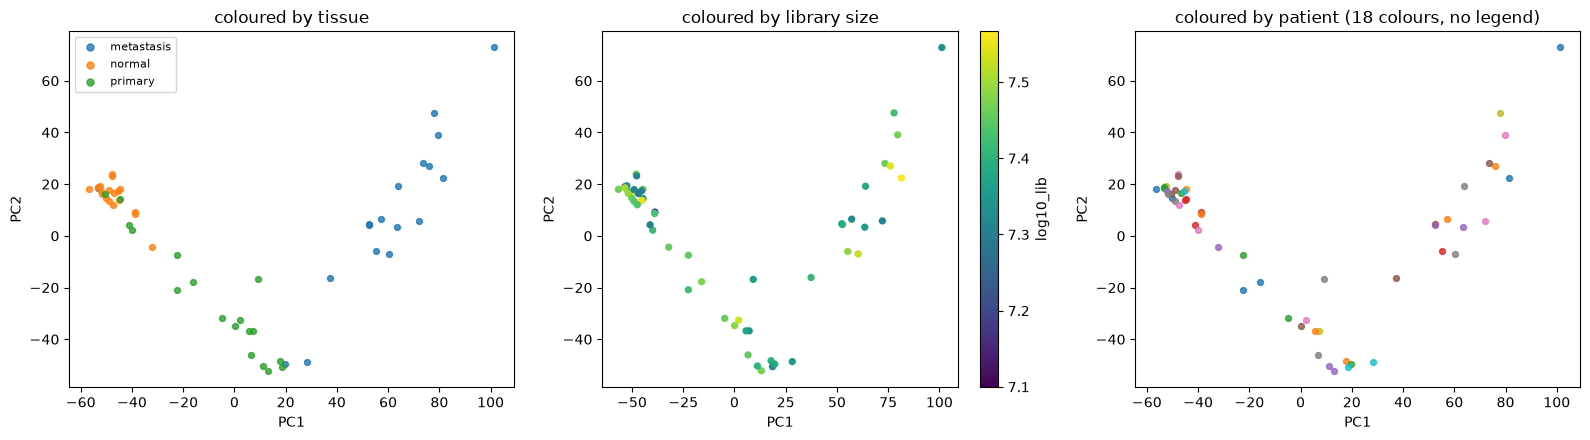

In [53]:
scores, variance = run_pca(logcpm)
print("% of variation explained by PC1 to PC5:", (100 * variance[:5]).round(1))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
plot_pca(scores, meta["tissue"], "coloured by tissue", ax[0])
meta["log10_lib"] = np.log10(meta["lib_size"])
plot_pca(scores, meta["log10_lib"], "coloured by library size", ax[1])
plot_pca(scores, meta["patient"], "coloured by patient (18 colours, no legend)", ax[2])
plt.tight_layout(); plt.show()

**Discussion.** Which PC separates the tissues best, and is it the PC with the most variation? Do the three tissues separate equally well? Is there a gradient with library size? Look at the patient colouring:
do samples from the same patient sit together? What does that tell you about the value of a *paired* analysis?

### 3.2 A clustering heatmap of the samples

PCA squeezes the data into two or three dimensions. Another view is to ask which samples are most **correlated** with each other across all genes, and let the computer group them (hierarchical clustering).

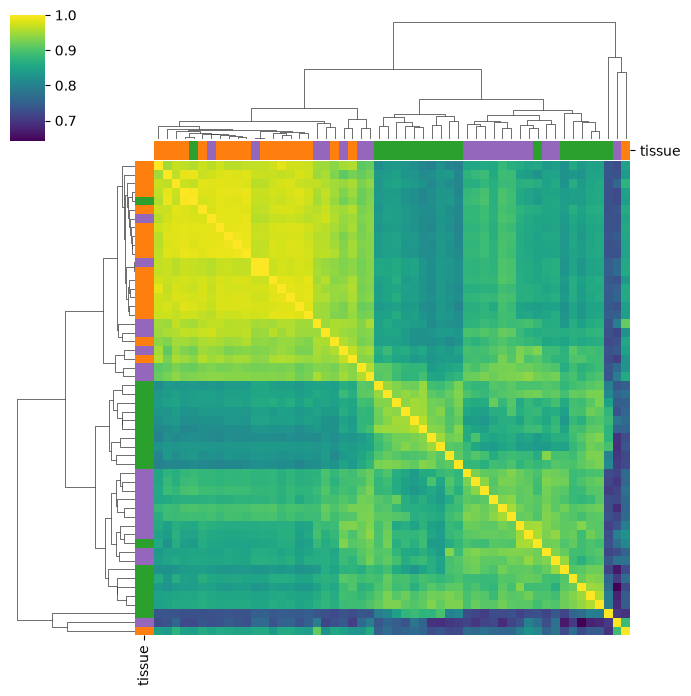

In [54]:
# Sample-by-sample correlation. Spearman uses only the RANKS of expression, so it is not dominated by a few very high genes.
corr = logcpm.corr(method="spearman")
bar = meta["tissue"].map({"normal": "tab:orange", "primary": "tab:purple", "metastasis": "tab:green"})
g = sns.clustermap(corr, method="average", cmap="viridis", row_colors=bar, col_colors=bar,
                   xticklabels=False, yticklabels=False, figsize=(7, 7))
plt.show()

**Discussion.** Do samples cluster by tissue, by patient, or both? Which samples look like outliers? Orange = normal, purple = primary, green = metastasis. If a sample clustered with the wrong group, list three possible explanations
(think: mix-up, low tumour purity, a different tissue).

### 3.3 t-SNE: not the same as PCA

t-SNE is a non-linear embedding used to look at neighbourhood structure. It has a setting called **perplexity** (roughly, how many neighbours each point pays attention to), and it starts from a random layout.
Run it first with different perplexities, then with different seeds.

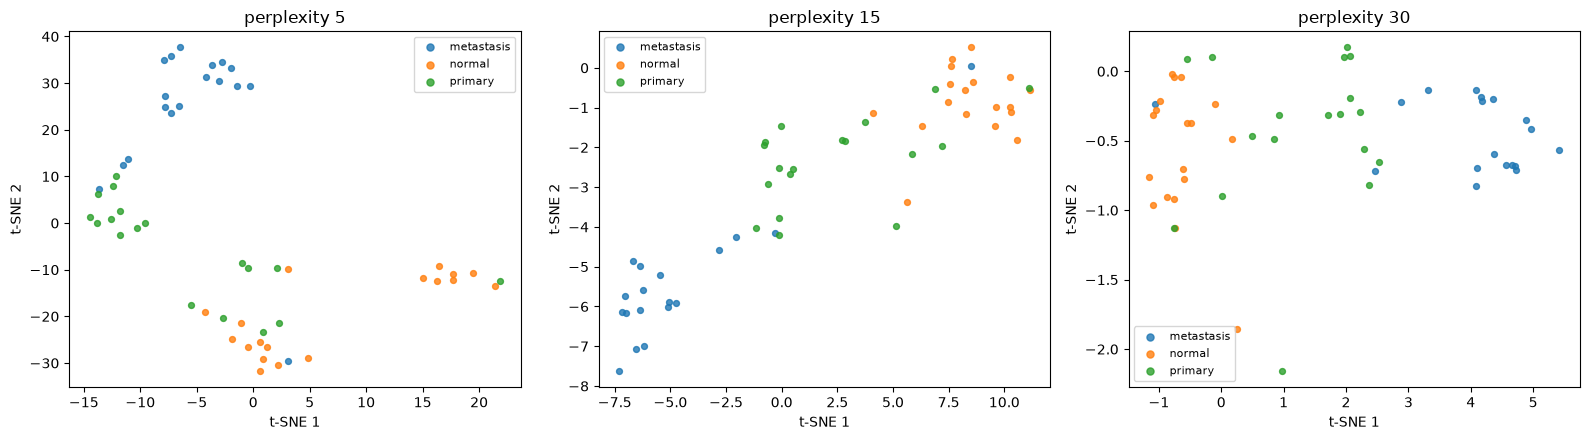

In [55]:
from sklearn.manifold import TSNE
X10 = scores.iloc[:, :10].to_numpy()          # t-SNE is run on the first 10 PCs

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, perp in zip(ax, (5, 15, 30)):
    emb = TSNE(n_components=2, perplexity=perp, init="pca", random_state=0).fit_transform(X10)
    emb = pd.DataFrame(emb, index=scores.index, columns=["t-SNE 1", "t-SNE 2"])
    plot_pca(emb, meta["tissue"], f"perplexity {perp}", a, pcs=("t-SNE 1", "t-SNE 2"))
plt.tight_layout(); plt.show()

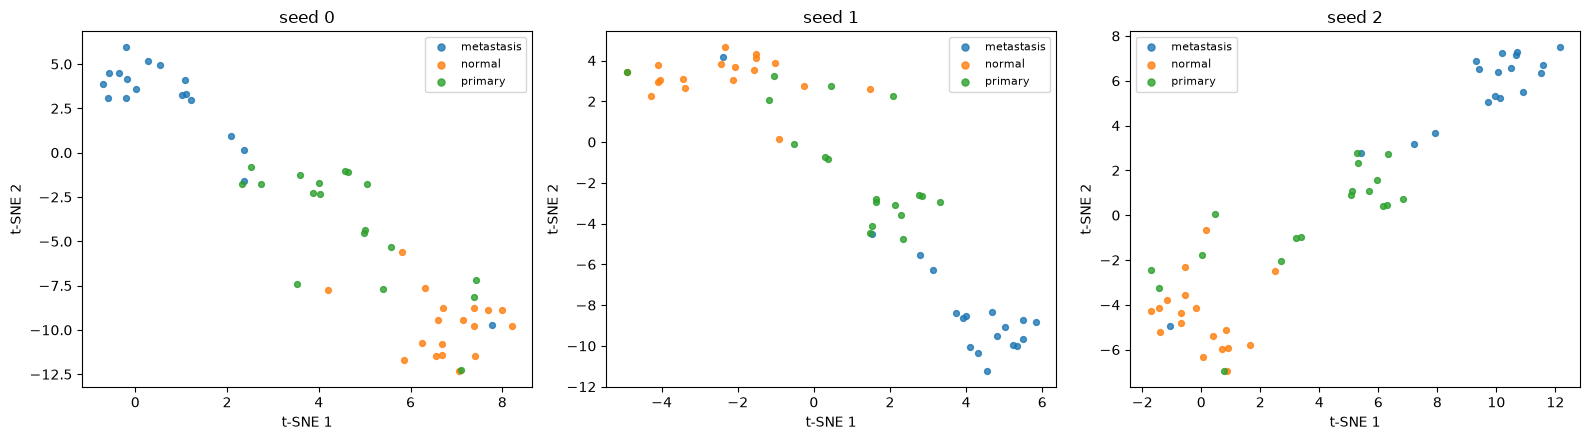

In [56]:
# Same data, same perplexity, different random starting layout.
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, seed in zip(ax, (0, 1, 2)):
    emb = TSNE(n_components=2, perplexity=15, init="random", random_state=seed).fit_transform(X10)
    emb = pd.DataFrame(emb, index=scores.index, columns=["t-SNE 1", "t-SNE 2"])
    plot_pca(emb, meta["tissue"], f"seed {seed}", a, pcs=("t-SNE 1", "t-SNE 2"))
plt.tight_layout(); plt.show()

**Discussion.** What stays the same across perplexities and seeds, and what changes? With only 54 samples, what goes wrong if perplexity is too large? Would you report the distance between two t-SNE clusters, or the size of a cluster, as a result?

## Part 4. Differential expression with PyDESeq2

### 4.1 The idea

**In plain English.** For every gene we ask: *is its expression different between the tumour and the normal sample of the same patient, by more than random variation would produce?* The test needs to cope with counts (not bell-curve data), with
a variance that grows with the mean, and with very few samples per group. **DESeq2** does this with a statistical model for counts, and **PyDESeq2** is its Python version. Three things go in: the **raw counts**, a **table of sample information**, and a
**design formula**. The formula `~ patient + tissue` says: allow each patient to have their own baseline, and estimate the tissue effect *on top of that*. That is how the pairing is used.

In [57]:
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

# Normal vs primary only (36 samples = 18 patients x 2). PyDESeq2 wants samples as ROWS and genes as COLUMNS, as integers.
pair = meta["tissue"].isin(["normal", "primary"])
counts_np = counts_f.loc[:, pair].T.round().astype(int)
sample_info = meta.loc[pair, ["patient", "tissue"]].copy()
sample_info["patient"] = "P" + sample_info["patient"].astype(str)     # make patient a label, not a number
print(counts_np.shape, "samples x genes")
sample_info.head()

(36, 15739) samples x genes


,patient,tissue
GSM1228184,P2,primary
GSM1228185,P3,primary
GSM1228186,P5,primary
GSM1228187,P6,primary
GSM1228188,P7,primary


In [58]:
t0 = time.time()
# The design formula: a baseline for each ____ plus an effect of tissue.
dds = DeseqDataSet(counts=counts_np, metadata=sample_info, design="~ patient + tissue", quiet=True)
dds.deseq2()                              # estimate size factors, dispersions and the model for every gene
print("fitted in", round(time.time() - t0), "seconds")

fitted in 6 seconds


In [59]:
# Ask the question: primary compared with normal. The contrast is [factor, numerator level, denominator level].
stats = DeseqStats(dds, contrast=["tissue", "primary", "normal"], quiet=True)
stats.summary()
res = stats.results_df.sort_values("padj")
PROVENANCE["de_primary_vs_normal"] = {"design": "~ patient + tissue", "contrast": "primary vs normal", "n_samples": int(pair.sum()),
                                      "genes_tested": int(res["pvalue"].notna().sum()), "pydeseq2": pydeseq2.__version__}
res.head(10)

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
BEST4,1870.919730,-6.193373,0.419959,-14.747563,3.189781e-49,5.020396e-45
OTOP2,828.958217,-7.521150,0.568438,-13.231264,5.790495e-40,4.556830e-36
CA7,1647.374649,-5.421972,0.411308,-13.182280,1.109858e-39,5.822683e-36
SPIB,1381.920847,-4.618201,0.389990,-11.841855,2.371481e-32,9.331183e-29
KRT80,298.725722,5.304326,0.492731,10.765157,5.027585e-27,1.582583e-23
INHBA,441.582271,4.605275,0.444608,10.358058,3.846950e-25,1.009119e-21
ETV4,796.610228,3.963598,0.387239,10.235536,1.374320e-24,3.090061e-21
SH2D6,121.658124,-3.443372,0.339957,-10.128849,4.114658e-24,8.095074e-21
UNC5C,247.382163,-1.853139,0.183441,-10.102093,5.407542e-24,8.660869e-21
OTOP3,37.870295,-7.161203,0.709003,-10.100381,5.502807e-24,8.660869e-21


**Discussion.** Match the columns to Lecture 2: `baseMean`, `log2FoldChange`, `lfcSE`, `stat`, `pvalue`, `padj`. In your own words, what is the difference between `pvalue` and `padj`, and which one do you use to call a gene significant? A log2 fold change of 1 means how many times higher in tumour?

### 4.2 How many genes, and do the p-values behave?

genes tested: 15739
padj < 0.05: 8327 | and |log2FC| > 1: 2225
up in tumour: 793 | down in tumour: 1432


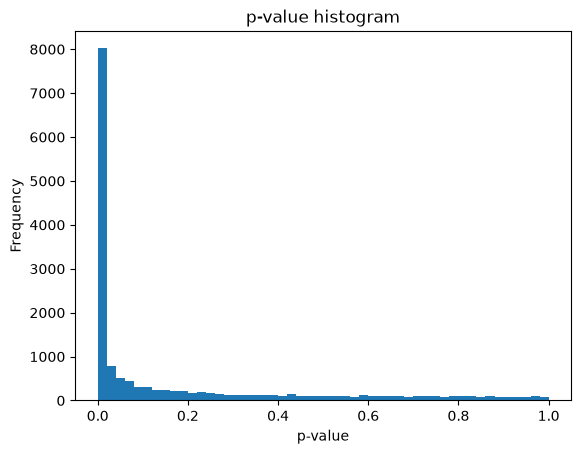

In [60]:
sig = (res["padj"] < 0.05) & (res["log2FoldChange"].abs() > 1)
print("genes tested:", int(res["pvalue"].notna().sum()))
print("padj < 0.05:", int((res["padj"] < 0.05).sum()), "| and |log2FC| > 1:", int(sig.sum()))
print("up in tumour:", int((sig & (res["log2FoldChange"] > 0)).sum()), "| down in tumour:", int((sig & (res["log2FoldChange"] < 0)).sum()))

res["pvalue"].dropna().plot.hist(bins=50)
plt.xlabel("p-value"); plt.title("p-value histogram"); plt.show()

**Discussion.** The p-value histogram should be roughly flat with a spike near 0. What does the flat part represent, and what does the spike represent? What would a histogram that is *U-shaped*, or one with *no spike at all*, suggest?

### 4.3 Volcano plot

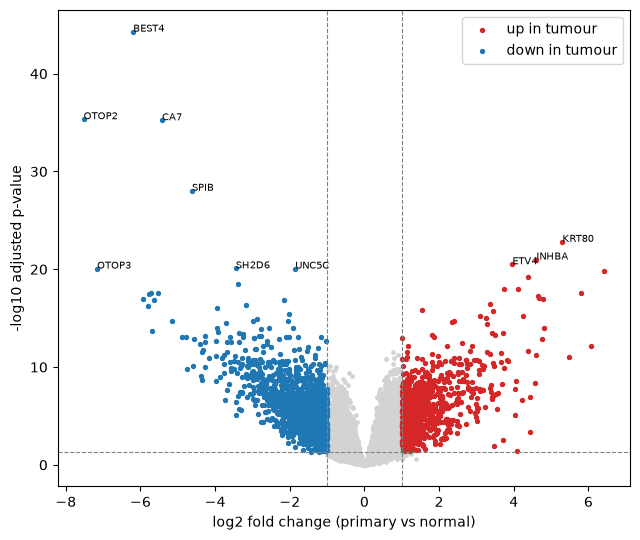

In [61]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
x = res["log2FoldChange"]
y = -np.log10(res["padj"])
ax.scatter(x, y, s=6, color="lightgrey")
up = sig & (x > 0); down = sig & (x < 0)
ax.scatter(x[up], y[up], s=8, color="tab:red", label="up in tumour")
ax.scatter(x[down], y[down], s=8, color="tab:blue", label="down in tumour")
for gene in res.dropna(subset=["padj"]).head(10).index:                      # label the ten smallest padj
    ax.annotate(gene, (x[gene], y[gene]), fontsize=7)
ax.axhline(-np.log10(0.05), ls="--", color="grey", lw=0.8); ax.axvline(-1, ls="--", color="grey", lw=0.8); ax.axvline(1, ls="--", color="grey", lw=0.8)
ax.set_xlabel("log2 fold change (primary vs normal)"); ax.set_ylabel("-log10 adjusted p-value"); ax.legend()
plt.tight_layout(); plt.show()

In [62]:
# Some genes you may expect to change in colorectal cancer. Which ones are in your results, and which way do they go?
check = ["GUCA2A", "GUCA2B", "CA1", "CA4", "MMP7", "MYC", "LGR5", "KRT20"]
res.reindex([g for g in check if g in res.index])[["baseMean", "log2FoldChange", "padj"]].round(3)

,baseMean,log2FoldChange,padj
GUCA2A,3818.415,-4.767,0.000
GUCA2B,1119.442,-5.927,0.000
CA1,13024.273,-5.789,0.000
CA4,4424.044,-3.952,0.000
MMP7,462.417,4.680,0.000
MYC,3556.558,1.361,0.000
LGR5,554.885,1.356,0.001
KRT20,19843.865,-2.400,0.000


## Part 5. Enrichment: what do the changed genes have in common?

### 5.1 Two ways to ask

**In plain English.** A list of over two thousand changed genes is not interpretable. We ask whether the list contains *more genes than expected from a known gene set* (for example the genes of a pathway).

- **Over-representation analysis (ORA):** take your significant genes, count how many fall in a gene set, and ask how surprising that overlap is given the gene set's size and the number of genes you tested (a hypergeometric test).
- **Gene set enrichment analysis (GSEA, "prerank"):** use *all* genes ranked by their test statistic, and ask whether the members of a gene set sit towards the top or the bottom of the list. No cut-off is needed.

Both need a library of gene sets. We use the **Hallmark** collection (50 well-curated sets, e.g. `Myc Targets V1`, `E2F Targets`, `Epithelial Mesenchymal Transition`).

In [63]:
import gseapy as gp
try:
    hallmark = gp.get_library("MSigDB_Hallmark_2020")                         # downloaded from Enrichr
    PROVENANCE["gene_sets"] = "MSigDB_Hallmark_2020 (downloaded via gseapy / Enrichr)"
except Exception as e:
    print("download failed:", type(e).__name__, "- using the local copy instead")
    hallmark = gp.read_gmt(str(CACHE / "MSigDB_Hallmark_2020.gmt"))
    PROVENANCE["gene_sets"] = "MSigDB_Hallmark_2020 (local copy geo_cache/MSigDB_Hallmark_2020.gmt)"
print(len(hallmark), "gene sets;", "sizes from", min(map(len, hallmark.values())), "to", max(map(len, hallmark.values())))
print(list(hallmark)[:8])

50 gene sets; sizes from 32 to 200
['TNF-alpha Signaling via NF-kB', 'Hypoxia', 'Cholesterol Homeostasis', 'Mitotic Spindle', 'Wnt-beta Catenin Signaling', 'TGF-beta Signaling', 'IL-6/JAK/STAT3 Signaling', 'DNA Repair']


### 5.2 One over-representation test by hand

In [64]:
from scipy.stats import hypergeom

background = list(res["pvalue"].dropna().index)               # every gene that was actually tested
up_genes = list(res.index[sig & (res["log2FoldChange"] > 0)])
down_genes = list(res.index[sig & (res["log2FoldChange"] < 0)])
print("tested:", len(background), "| up:", len(up_genes), "| down:", len(down_genes))

term = "Epithelial Mesenchymal Transition"                      # try others from the list above, e.g. "Myc Targets V1" (compare it with GSEA in 5.4)
set_genes = set(hallmark[term]) & set(background)               # only count set members that could have been tested
k = len(set(up_genes) & set_genes)                              # overlap between your up genes and the gene set
# hypergeom.sf(overlap - 1, genes tested, genes in the set, genes in your list) = probability of an overlap this big or bigger by chance
p = hypergeom.sf(k - 1, len(background), len(set_genes), len(up_genes))
print(f"{term}: set size {len(set_genes)}, overlap {k}, expected by chance {len(up_genes) * len(set_genes) / len(background):.1f}, p = {p:.2e}")

tested: 15739 | up: 793 | down: 1432
Epithelial Mesenchymal Transition: set size 198, overlap 63, expected by chance 10.0, p = 1.02e-33


**Discussion.** The test needs *four* numbers. Which one would change most if you used all genes in the genome instead of only the genes tested? Why is it wrong to use the whole genome as the background when many genes were never expressed in colon tissue?

### 5.3 All gene sets at once

In [65]:
for name, genes in [("UP in tumour", up_genes), ("DOWN in tumour", down_genes)]:
    enr = gp.enrichr(gene_list=genes, gene_sets=hallmark, background=background, outdir=None, no_plot=True)
    tab = enr.results.sort_values("Adjusted P-value")[["Term", "Overlap", "P-value", "Adjusted P-value", "Odds Ratio"]]
    print(name); print(tab.head(8).to_string(index=False)); print()

UP in tumour
                             Term Overlap      P-value  Adjusted P-value  Odds Ratio
Epithelial Mesenchymal Transition  63/198 1.021044e-33      4.798909e-32    9.501961
                      E2F Targets  37/199 4.129329e-12      9.703923e-11    4.509990
                  G2-M Checkpoint  36/196 1.169528e-11      1.832261e-10    4.439158
    TNF-alpha Signaling via NF-kB  34/196 2.191163e-10      2.574616e-09    4.132802
            Inflammatory Response  33/191 4.503053e-10      4.232870e-09    4.109987
                      Coagulation  23/132 1.677753e-07      1.314240e-06    4.132776
                     Angiogenesis   11/35 6.797433e-07      4.563990e-06    8.951359
           Estrogen Response Late  24/190 3.099204e-05      1.820782e-04    2.826392

DOWN in tumour
                  Term Overlap  P-value  Adjusted P-value  Odds Ratio
     KRAS Signaling Dn  29/136 0.000011          0.000468    2.776545
   Pancreas Beta Cells   11/33 0.000100          0.002099    5.136

**Discussion.** Which processes are enriched in the up genes, and which in the down genes? Do they make biological sense for colorectal cancer? Why do we analyse up and down genes *separately*, and what could be hidden if you pooled them?

### 5.4 GSEA: use the whole ranked list

In [66]:
# Rank every tested gene by its test statistic (`stat`): large positive = up in tumour, large negative = down.
ranking = res["stat"].dropna().sort_values(ascending=False)
pre = gp.prerank(rnk=ranking, gene_sets=hallmark, min_size=10, max_size=500, permutation_num=1000, seed=1, threads=2, no_plot=True, outdir=None)
gs = pre.res2d.copy()
gs["NES"] = gs["NES"].astype(float); gs["FDR q-val"] = gs["FDR q-val"].astype(float)
gs = gs.sort_values("NES", ascending=False)
print(gs[["Term", "ES", "NES", "NOM p-val", "FDR q-val"]].head(6).to_string(index=False))
print(gs[["Term", "ES", "NES", "NOM p-val", "FDR q-val"]].tail(6).to_string(index=False))

2026-11-19 08:19:33,944 [WARNING] Duplicated values found in preranked stats: 0.01% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


                     Term       ES      NES  NOM p-val  FDR q-val
              E2F Targets 0.685265 3.641571        0.0        0.0
           Myc Targets V1 0.674147 3.629718        0.0        0.0
          G2-M Checkpoint 0.635345 3.383906        0.0        0.0
           Myc Targets V2 0.770841 3.268846        0.0        0.0
Unfolded Protein Response 0.539069 2.655324        0.0        0.0
         mTORC1 Signaling 0.498732 2.650855        0.0        0.0
                     Term        ES       NES  NOM p-val  FDR q-val
     Bile Acid Metabolism -0.389465 -1.807811        0.0   0.001285
      Pancreas Beta Cells -0.507362 -1.853189        0.0   0.000578
    Fatty Acid Metabolism -0.402000 -1.982195        0.0   0.000000
          heme Metabolism -0.400636 -2.037712        0.0   0.000000
             Adipogenesis -0.425997 -2.197175        0.0   0.000000
Oxidative Phosphorylation -0.450778 -2.320280        0.0   0.000000


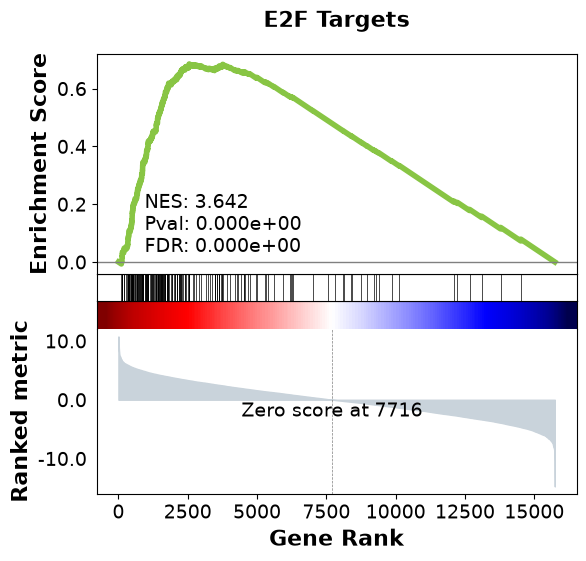

In [67]:
# The running-score plot of the top gene set: a high peak at the left means its genes are concentrated among the most up-regulated genes.
from gseapy import gseaplot
top_term = gs["Term"].iloc[0]
gseaplot(rank_metric=pre.ranking, term=top_term, **pre.results[top_term])
plt.show()

**Discussion.** Do ORA and GSEA agree on the top gene sets? (Go back to 5.2, set `term = "Myc Targets V1"` and compare: how does ORA treat the set that GSEA ranks near the top, and why?) Which one needed an arbitrary cut-off? Several Hallmark sets share many genes: what does this do to the idea that each significant set is an *independent* finding? Name one way tumour purity (Lecture 2) could create an enriched set that is not about the cancer cells themselves.

### 5.5 The web-tools worksheet again, in code

Before this notebook you pasted lists into Enrichr, g:Profiler and MetaboAnalyst by hand. Here you repeat the gene-list part in a few lines, using the lists from the worksheet and the Hallmark sets you already loaded. Notice which choices you now **control** (the background) and which the web forms made for you. The results will not match the web tools exactly: they used much larger libraries than the 50 Hallmark sets.

In [68]:
# The same lists as on the worksheet (from the TCGA colorectal paper and Yu et al. 2019, Table II).
list_A = ["APC", "TP53", "KRAS", "PIK3CA", "FBXW7", "SMAD4", "TCF7L2", "NRAS", "CTNNB1", "SMAD2", "FAM123B", "SOX9", "ACVR2A", "TGFBR2", "MSH3", "MSH6", "SLC9A9"]
list_B_up = ["FOXQ1", "KRT23", "LY6G6D", "MMP7", "CDH3", "MMP3", "CST1", "CRNDE", "DPEP1", "MMP1", "EPHX4", "CTHRC1", "CLDN1", "CEL", "CLDN2", "SLC35D3", "COL11A1", "CXCL3", "SLCO1B3", "CKMT2"]
list_B_down = ["AQP8", "CLCA4", "GUCA2B", "MS4A12", "GUCA2A", "CA2", "ABCG2", "CLDN8", "GCG", "ZG16", "PKIB", "CA4", "BEST4", "CA1", "MT1M", "CD177", "HSD17B2", "INSL5", "ADH1C", "CLCA1"]
list_B = list_B_up + list_B_down                                  # the 40 genes of Table II
hub_genes = ["TOP2A", "MAD2L1", "CCNB1", "CHEK1", "CDC6", "UBE2C"]   # the six hub genes the paper names
tested = set(background)                                           # the genes tested in YOUR experiment (section 5.2)
for name, genes in [("List A", list_A), ("List B (40 DE genes)", list_B), ("hub genes", hub_genes)]:
    found = [g for g in genes if g in tested]
    missing = [g for g in genes if g not in tested]
    print(f"{name}: {len(found)} of {len(genes)} are among the genes tested. Not found: {missing}")

List A: 16 of 17 are among the genes tested. Not found: ['FAM123B']
List B (40 DE genes): 39 of 40 are among the genes tested. Not found: ['CRNDE']
hub genes: 6 of 6 are among the genes tested. Not found: []


**Discussion.** The web tools told you how many genes they recognised. Here you can see *why* a gene is missing: the symbol is old (FAM123B is now AMER1), the gene is not protein-coding and our filter removed it (CRNDE), or it was filtered out because of low counts. Which of those reasons could a web tool never tell you about?

In [69]:
def enrich(genes, bg, label, top=5):
    enr = gp.enrichr(gene_list=genes, gene_sets=hallmark, background=bg, outdir=None, no_plot=True)
    if not hasattr(enr.results, "sort_values"):                  # gseapy returns an empty list when no gene set overlaps at all
        print(f"{label}: no Hallmark set overlaps these genes at all\n"); return None
    tab = enr.results.sort_values("Adjusted P-value")
    n_sig = int((tab["Adjusted P-value"] < 0.05).sum())
    print(f"{label}: {n_sig} Hallmark sets with adjusted p < 0.05")
    print(tab[["Term", "Overlap", "Adjusted P-value"]].head(top).to_string(index=False)); print()
    return tab

# Background 1: the genes you actually tested.  Background 2: a deliberately narrow list (what you pasted into g:Profiler).
narrow = list(dict.fromkeys(list_A + hub_genes))
_ = enrich([g for g in list_A if g in tested], background, "List A, tested genes as background")
_ = enrich([g for g in list_A if g in set(narrow)], narrow, "List A, narrow background")

List A, tested genes as background: 3 Hallmark sets with adjusted p < 0.05
                      Term Overlap  Adjusted P-value
        TGF-beta Signaling    2/53          0.010363
Wnt-beta Catenin Signaling    2/40          0.010363
            UV Response Dn   2/143          0.048264
               p53 Pathway   2/196          0.066032
           Notch Signaling    1/32          0.102574

List A, narrow background: 0 Hallmark sets with adjusted p < 0.05
                   Term Overlap  Adjusted P-value
    Allograft Rejection     1/1          0.909699
Cholesterol Homeostasis     1/1          0.909699
             Complement     1/1          0.909699
             DNA Repair     1/1          0.909699
             Glycolysis     1/1          0.909699



**Discussion.** Compare with what you saw in g:Profiler when you changed the background. Why does a narrow background remove almost every significant set? In the web tool you had to remember which background you used; where is it recorded here?

## Part 6. Showing the pathway results as figures

Tables of p-values are hard to read and hard to put in a report. Here you turn the pathway results from Part 5 into two figures: **(1)** the top pathways from the over-representation test (ORA, section 5.2), and **(2)** the top pathways from GSEA (section 5.4). Change `TOP_N` to show more or fewer pathways.

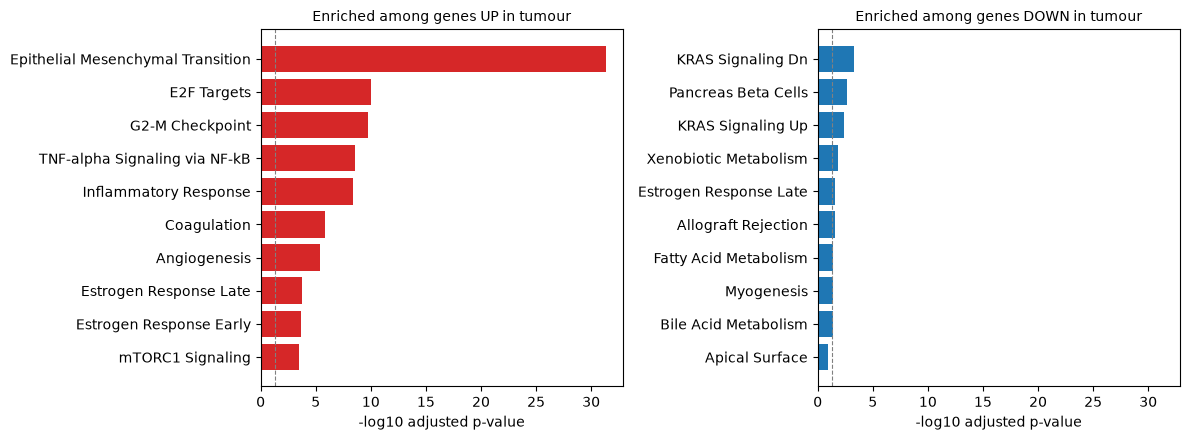

In [71]:
TOP_N = 10                                    # how many pathways to show per direction (try 5 or 15)

def ora_table(genes):
    """Over-representation of Hallmark sets among `genes`, tested against the genes we actually measured."""
    enr = gp.enrichr(gene_list=genes, gene_sets=hallmark, background=background, outdir=None, no_plot=True)
    return enr.results.sort_values("Adjusted P-value")

ora_up, ora_down = ora_table(up_genes), ora_table(down_genes)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
for ax, tab, title, colour in [(axes[0], ora_up, "Enriched among genes UP in tumour", "tab:red"),
                               (axes[1], ora_down, "Enriched among genes DOWN in tumour", "tab:blue")]:
    top = tab.head(TOP_N).iloc[::-1]                       # reversed, so the best pathway is drawn at the top
    score = -np.log10(top["Adjusted P-value"])                           # a longer bar means stronger evidence
    ax.barh(top["Term"], score, color=colour)
    ax.axvline(-np.log10(0.05), ls="--", color="grey", lw=0.8)    # bars beyond this line have adjusted p < 0.05
    ax.set_title(title, fontsize=10); ax.set_xlabel("-log10 adjusted p-value")
plt.tight_layout(); plt.savefig("pathways_ora.png", dpi=150); plt.show()

**Discussion.** Which pathways are enriched among the up genes, and which among the down genes? Do the two panels tell a sensible biological story for tumour versus normal colon (think: cell division, immune and stromal signals, the normal gut lining)? A bar that does not reach the dashed line is **not** significant; what does that mean for pathways ranked 8 to 10?

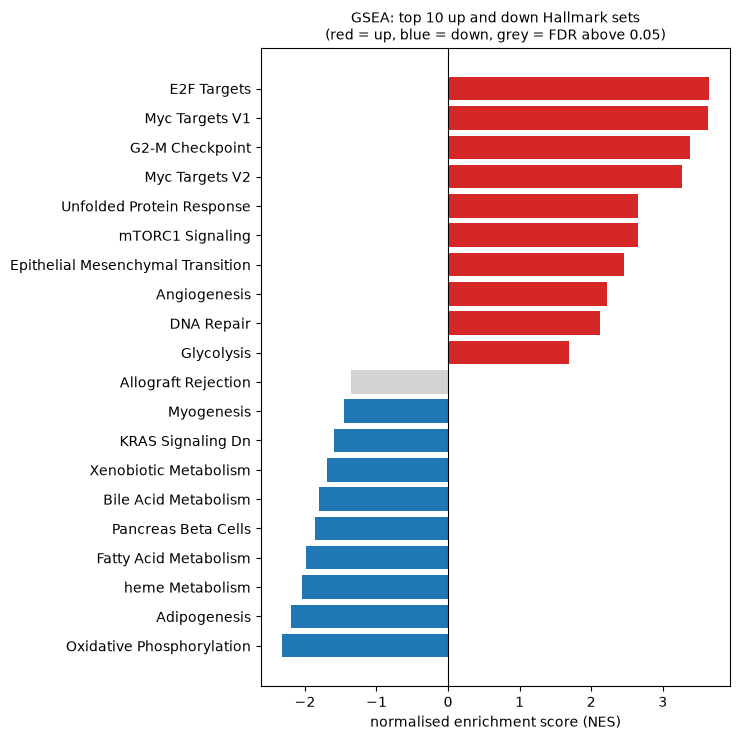

In [72]:
# GSEA uses the whole ranked gene list, so every pathway gets a score (NES): positive = up in tumour, negative = down.
top_up = gs.sort_values("NES", ascending=False).head(TOP_N)
top_down = gs.sort_values("NES").head(TOP_N)                # ascending order, so the most negative scores come first
show = pd.concat([top_up, top_down]).drop_duplicates("Term").sort_values("NES")

# Colour the bars that pass the FDR threshold; grey ones are not significant.
colours = np.where(show["FDR q-val"] < 0.05, np.where(show["NES"] > 0, "tab:red", "tab:blue"), "lightgrey")
fig, ax = plt.subplots(figsize=(7.5, 0.3 * len(show) + 1.5))
ax.barh(show["Term"], show["NES"], color=colours)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("normalised enrichment score (NES)")
ax.set_title(f"GSEA: top {TOP_N} up and down Hallmark sets\n(red = up, blue = down, grey = FDR above 0.05)", fontsize=10)
plt.tight_layout(); plt.savefig("pathways_gsea.png", dpi=150); plt.show()

**Discussion.** Compare the two figures. Which pathways appear in both? Which appear in only one, and why might that be (hint: ORA only sees the genes that passed your cut-offs, GSEA uses every gene)? Which figure would you put in a report, and what would you write in the caption?